# 02 — Naive Bayes (Multinomial, Bernoulli, Complement)

**Algorithms:** MultinomialNB · BernoulliNB · ComplementNB  
**Features:** TF-IDF (50K unigrams + bigrams)  
All three Naive Bayes variants assume feature independence. ComplementNB is specifically designed for imbalanced text classification.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve, plot_learning_curve, get_proba)
from sklearn.metrics import accuracy_score, roc_auc_score
BASE_DIR, FIGURES_DIR = setup_paths()

In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905


In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2),
                        sublinear_tf=True, min_df=2, max_df=0.95)
X_tr = tfidf.fit_transform(X_train)
X_te = tfidf.transform(X_test)
print(f'TF-IDF shape: {X_tr.shape}')

TF-IDF shape: (83616, 50000)


## Train All Three NB Variants

In [4]:
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, ComplementNB

nb_models = [
    ('Multinomial NB', MultinomialNB(alpha=0.1)),
    ('Bernoulli NB',   BernoulliNB()),
    ('Complement NB',  ComplementNB()),
]

results = {}
for name, model in nb_models:
    t0 = time.time()
    model.fit(X_tr, y_train)
    elapsed = time.time() - t0
    m, y_pred, y_prob = evaluate_and_print(model, X_te, y_test, name, elapsed)
    results[name] = {'model': model, 'metrics': m, 'y_pred': y_pred, 'y_prob': y_prob, 'time': elapsed}


  Multinomial NB — Evaluation Results
  Accuracy          : 0.7724
  Precision         : 0.7749
  Recall            : 0.7724
  F1 Score          : 0.7733
  AUC-ROC           : 0.8707
  Train Time (s)    : 0.28s

              precision    recall  f1-score   support

    Fake (0)       0.71      0.75      0.73      8532
    Real (1)       0.82      0.79      0.80     12373

    accuracy                           0.77     20905
   macro avg       0.76      0.77      0.77     20905
weighted avg       0.77      0.77      0.77     20905


  Bernoulli NB — Evaluation Results
  Accuracy          : 0.7305
  Precision         : 0.7315
  Recall            : 0.7305
  F1 Score          : 0.7203
  AUC-ROC           : 0.7245
  Train Time (s)    : 0.39s

              precision    recall  f1-score   support

    Fake (0)       0.74      0.53      0.62      8532
    Real (1)       0.73      0.87      0.79     12373

    accuracy                           0.73     20905
   macro avg       0.73      0.

## Side-by-Side Metric Comparison

                Accuracy  Precision  Recall  F1 Score  AUC-ROC  Train Time (s)
Multinomial NB    0.7724     0.7749  0.7724    0.7733   0.8707            0.28
Bernoulli NB      0.7305     0.7315  0.7305    0.7203   0.7245            0.39
Complement NB     0.7578     0.7755  0.7578    0.7599   0.8697            0.20


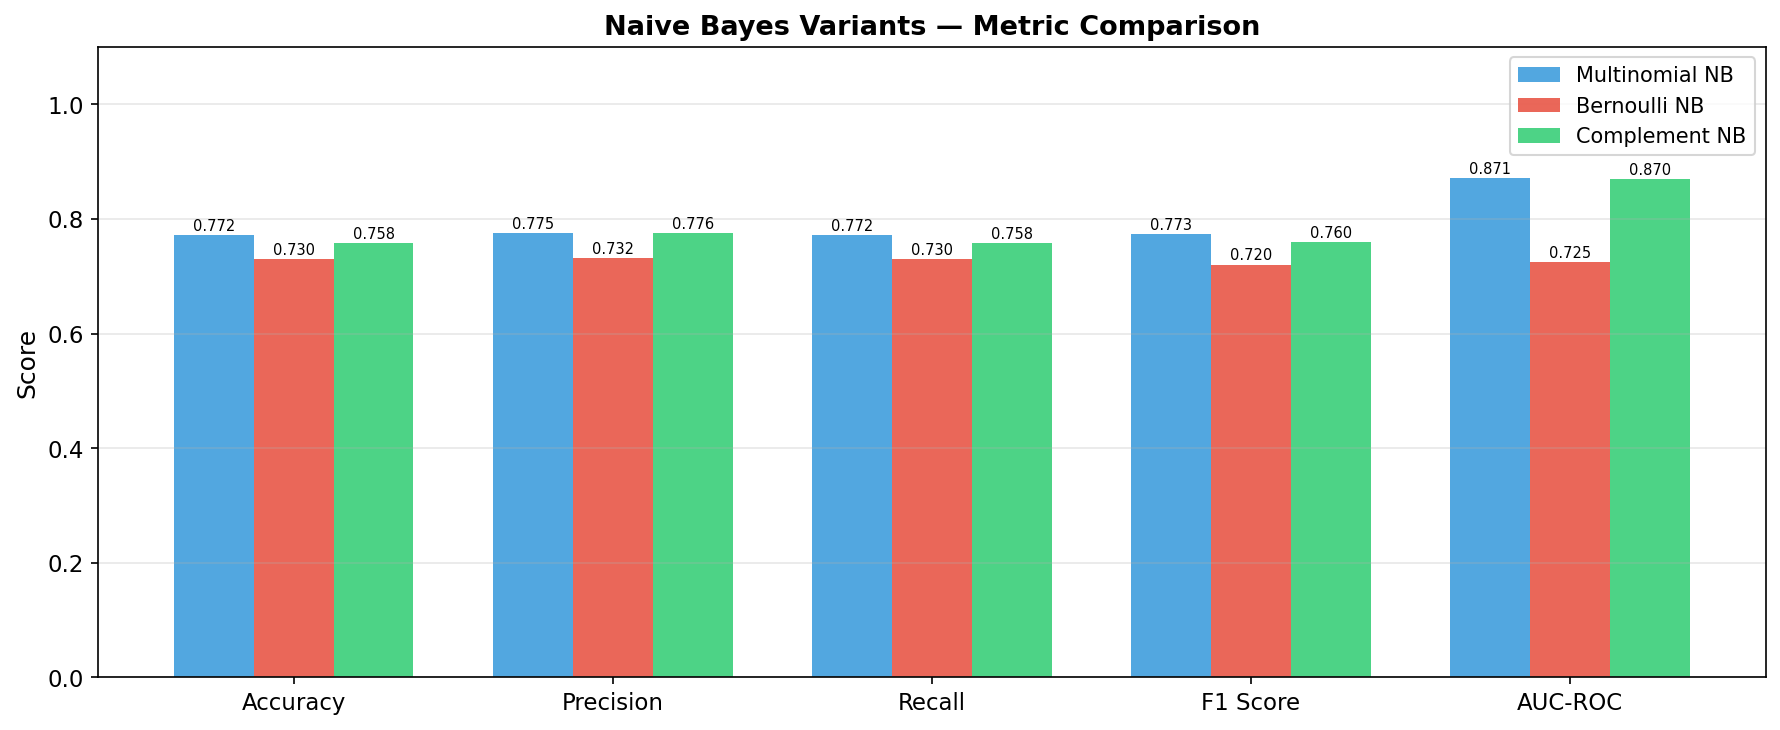

In [5]:
comp = pd.DataFrame({name: v['metrics'] for name, v in results.items()}).T
print(comp.round(4).to_string())

metric_cols = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']
x = np.arange(len(metric_cols))
colors = ['#3498db', '#e74c3c', '#2ecc71']
fig, ax = plt.subplots(figsize=(12, 5))
width = 0.25
for i, (name, row) in enumerate(comp.iterrows()):
    vals = [row[m] for m in metric_cols]
    bars = ax.bar(x + i*width - width, vals, width, label=name,
                  color=colors[i], alpha=0.85)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                f'{v:.3f}', ha='center', va='bottom', fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(metric_cols, fontsize=11)
ax.set_ylabel('Score')
ax.set_title('Naive Bayes Variants — Metric Comparison')
ax.legend(fontsize=10)
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'naive_bayes_comparison.png'), dpi=150, bbox_inches='tight')
plt.show()

## Confusion Matrices

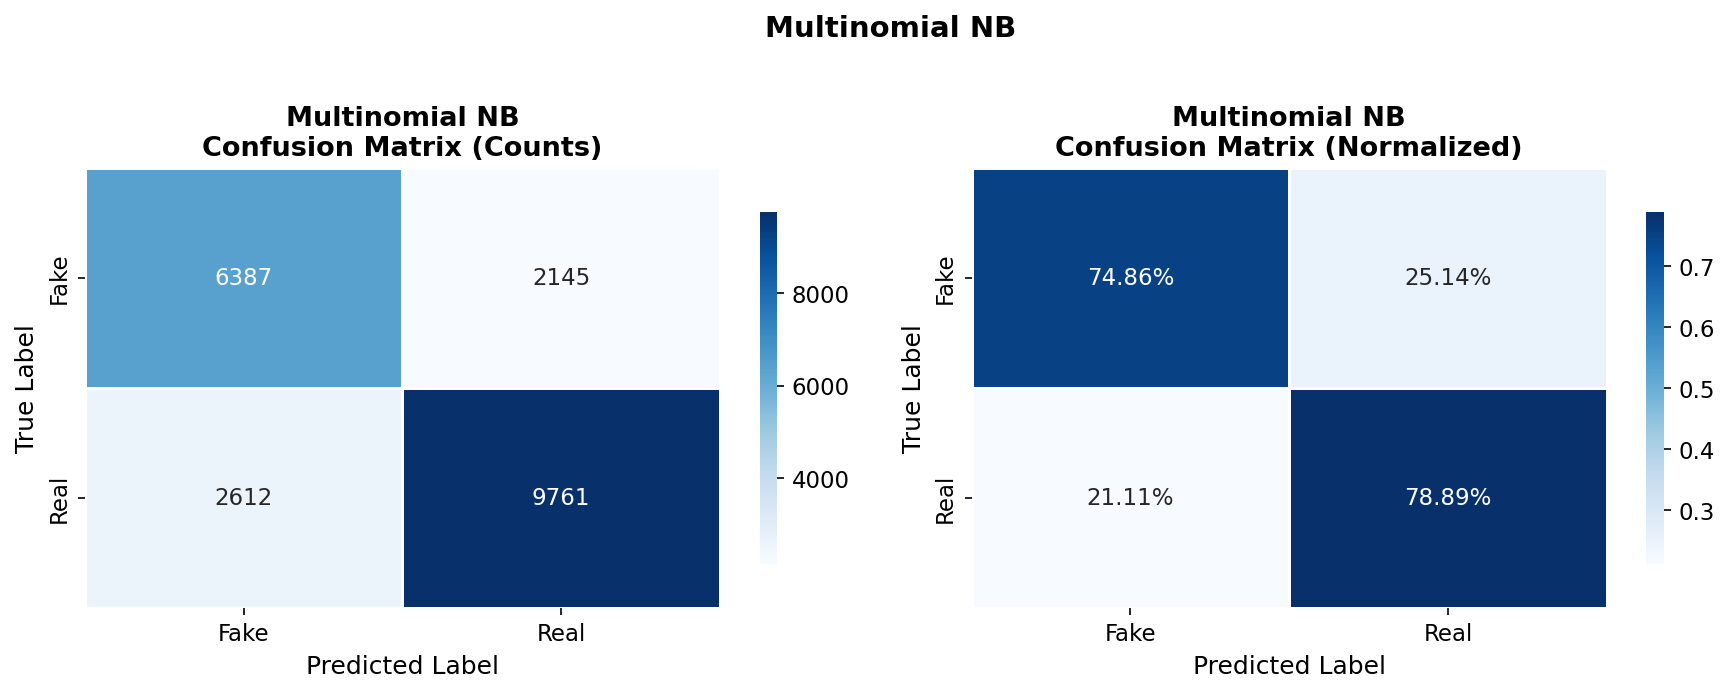

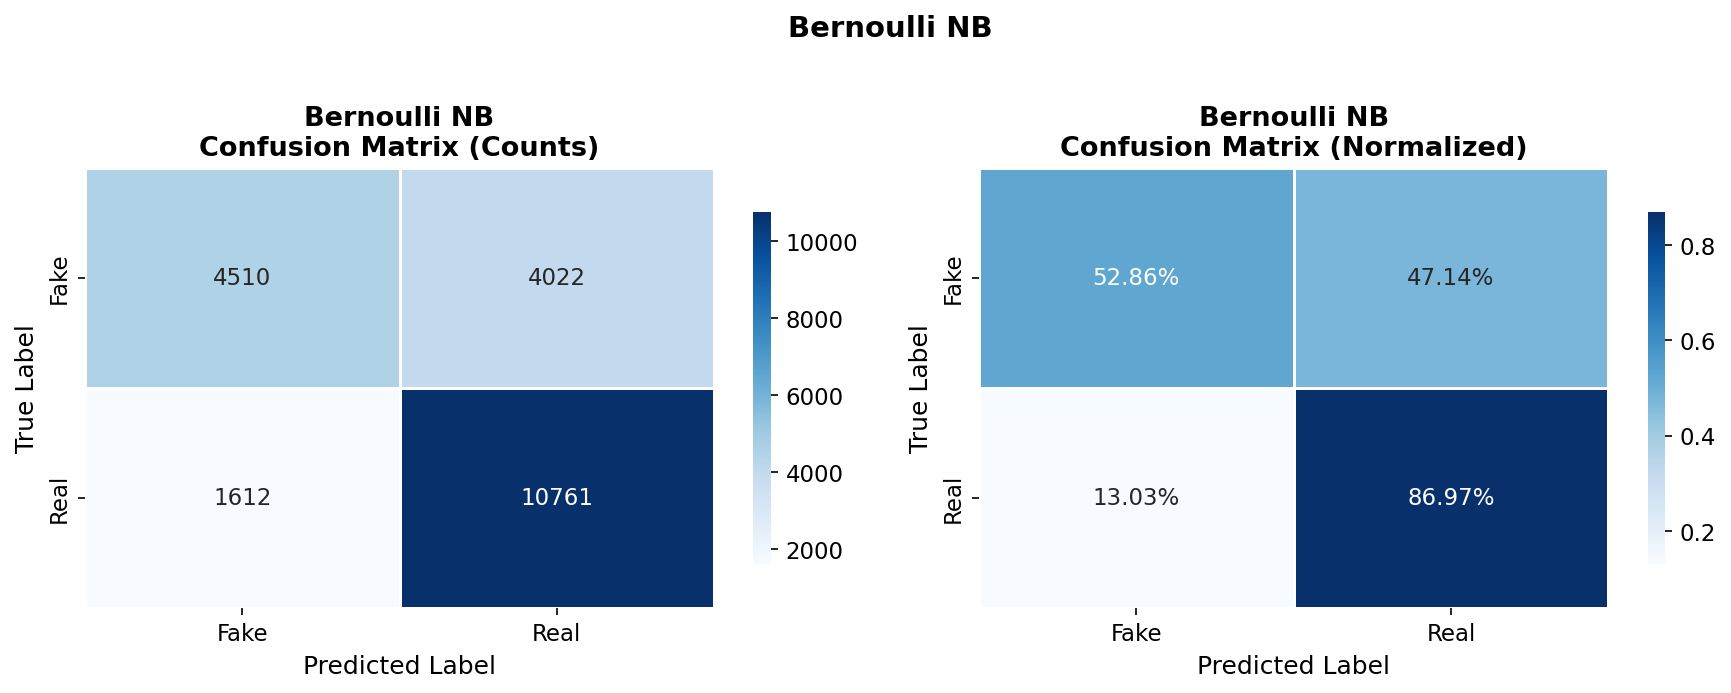

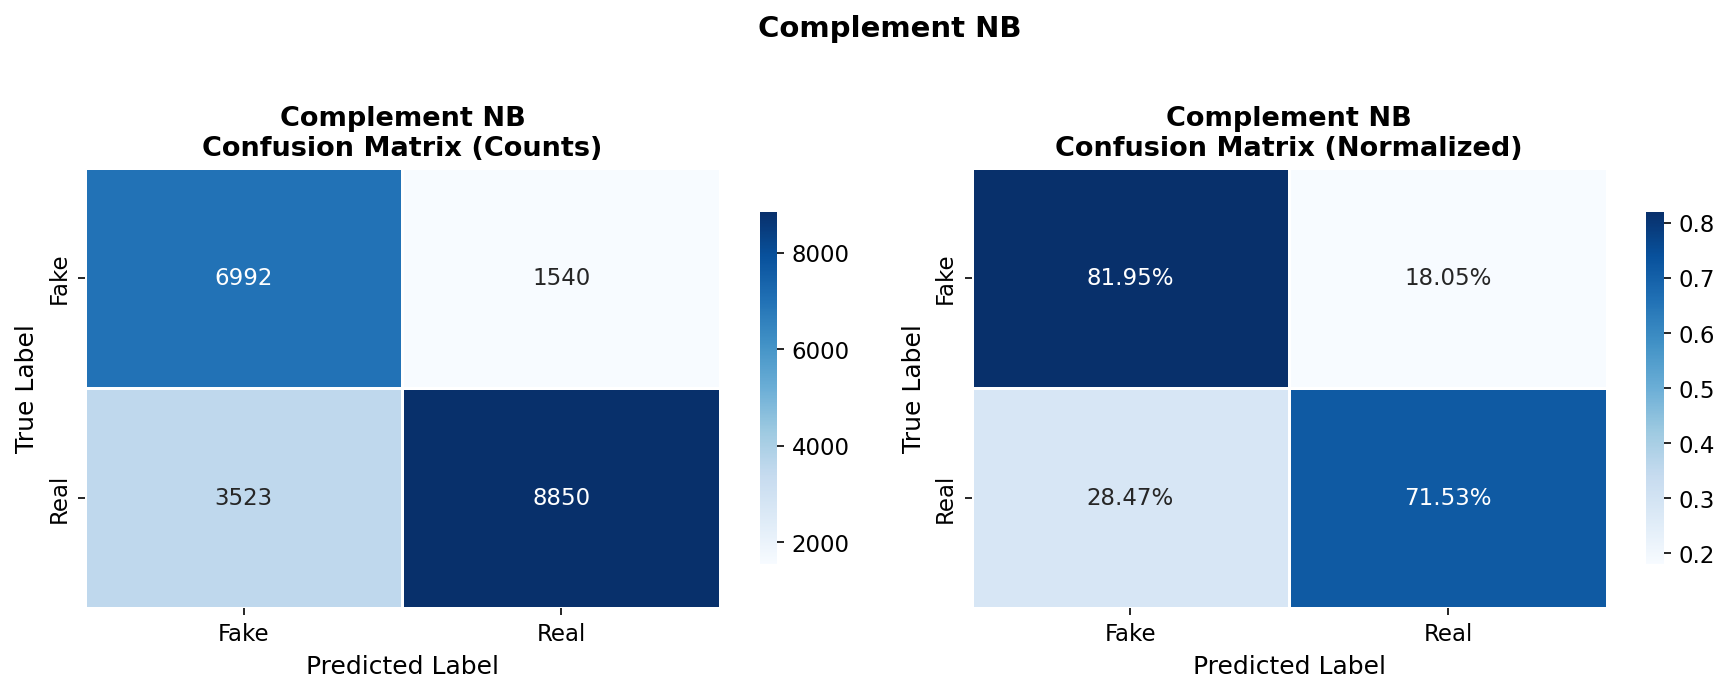

In [6]:
for name, v in results.items():
    plot_confusion_matrix(y_test, v['y_pred'], name, FIGURES_DIR)

## ROC Curves (Overlaid)

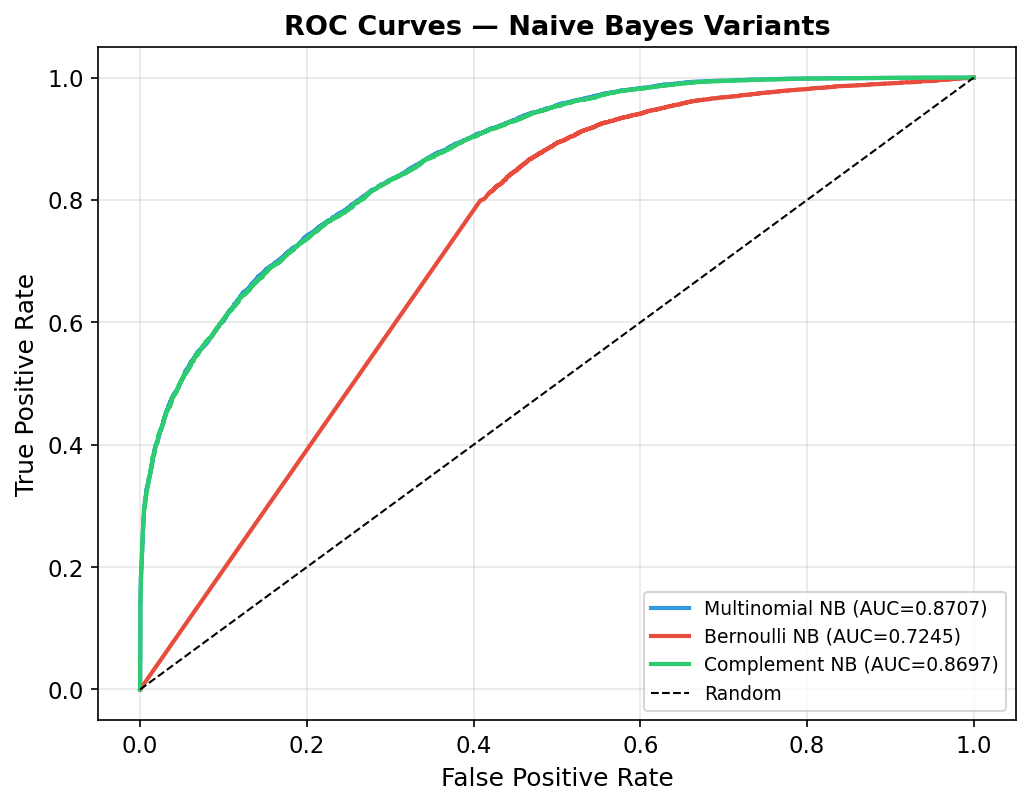

In [7]:
from sklearn.metrics import roc_curve
colors = ['#3498db', '#e74c3c', '#2ecc71']
fig, ax = plt.subplots(figsize=(7, 5.5))
for (name, v), color in zip(results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, v['y_prob'])
    auc = roc_auc_score(y_test, v['y_prob'])
    ax.plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC={auc:.4f})')
ax.plot([0,1],[0,1],'k--', lw=1, label='Random')
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves — Naive Bayes Variants')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'naive_bayes_roc.png'), dpi=150, bbox_inches='tight')
plt.show()

## Precision-Recall Curves (Overlaid)

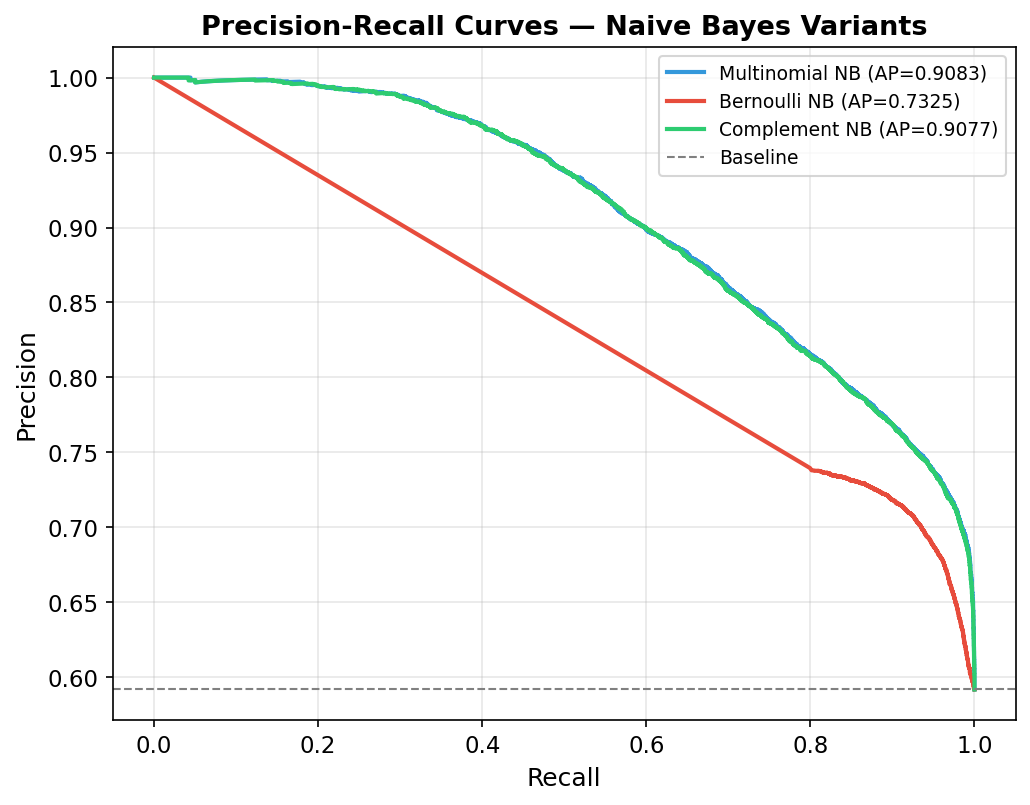

In [8]:
from sklearn.metrics import precision_recall_curve, average_precision_score
fig, ax = plt.subplots(figsize=(7, 5.5))
for (name, v), color in zip(results.items(), colors):
    prec, rec, _ = precision_recall_curve(y_test, v['y_prob'])
    ap = average_precision_score(y_test, v['y_prob'])
    ax.plot(rec, prec, color=color, lw=2, label=f'{name} (AP={ap:.4f})')
ax.axhline(y_test.mean(), color='grey', linestyle='--', lw=1, label='Baseline')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curves — Naive Bayes Variants')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'naive_bayes_pr.png'), dpi=150, bbox_inches='tight')
plt.show()

## Learning Curves

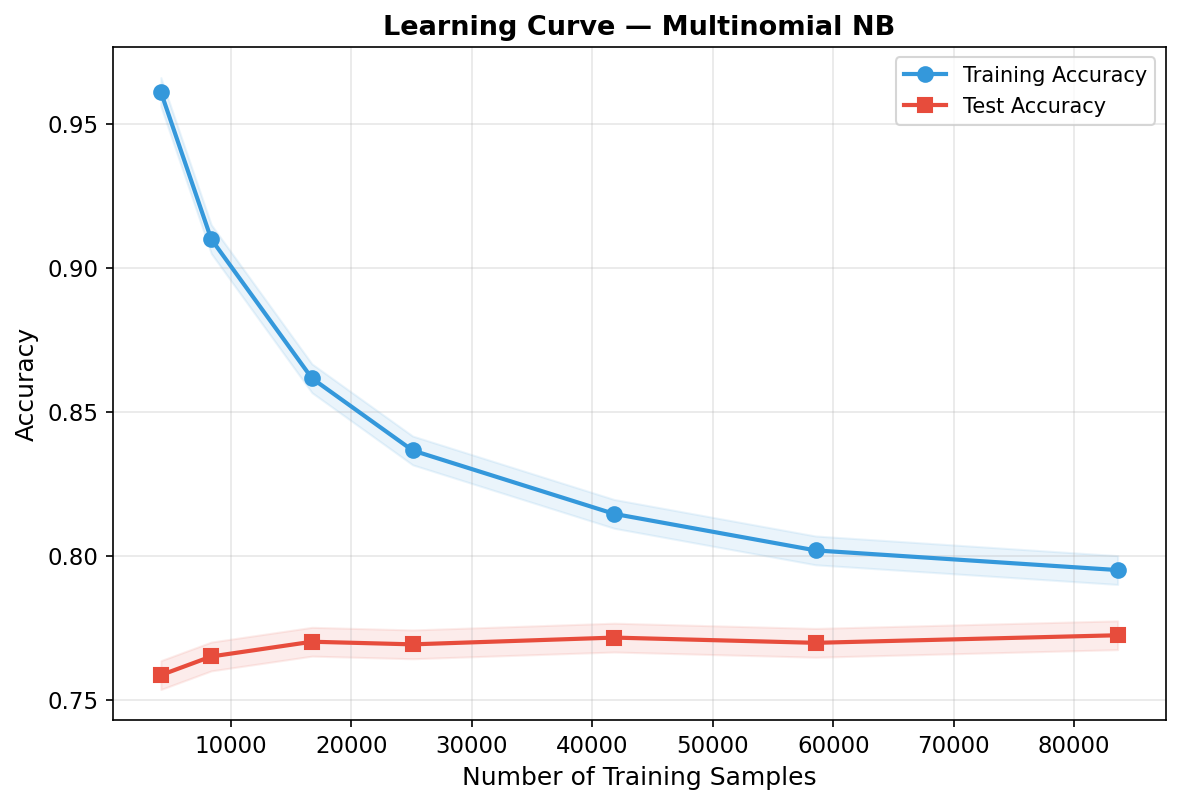

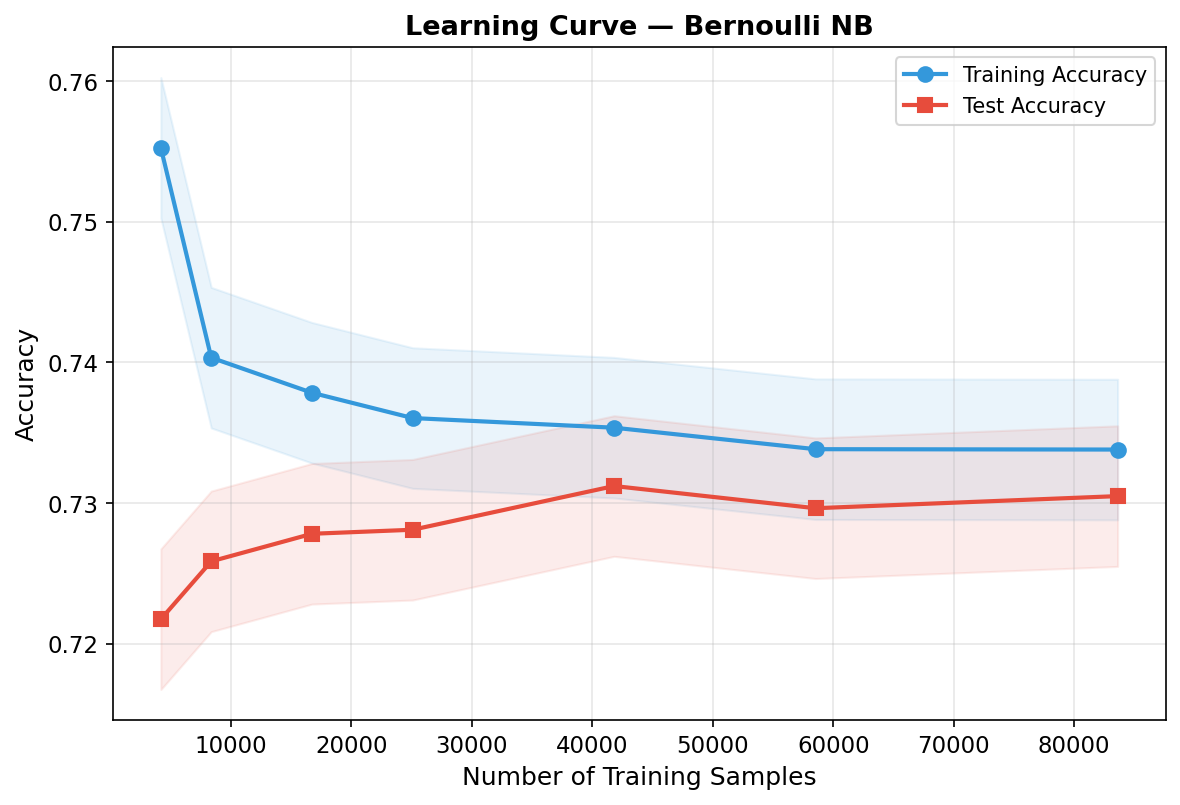

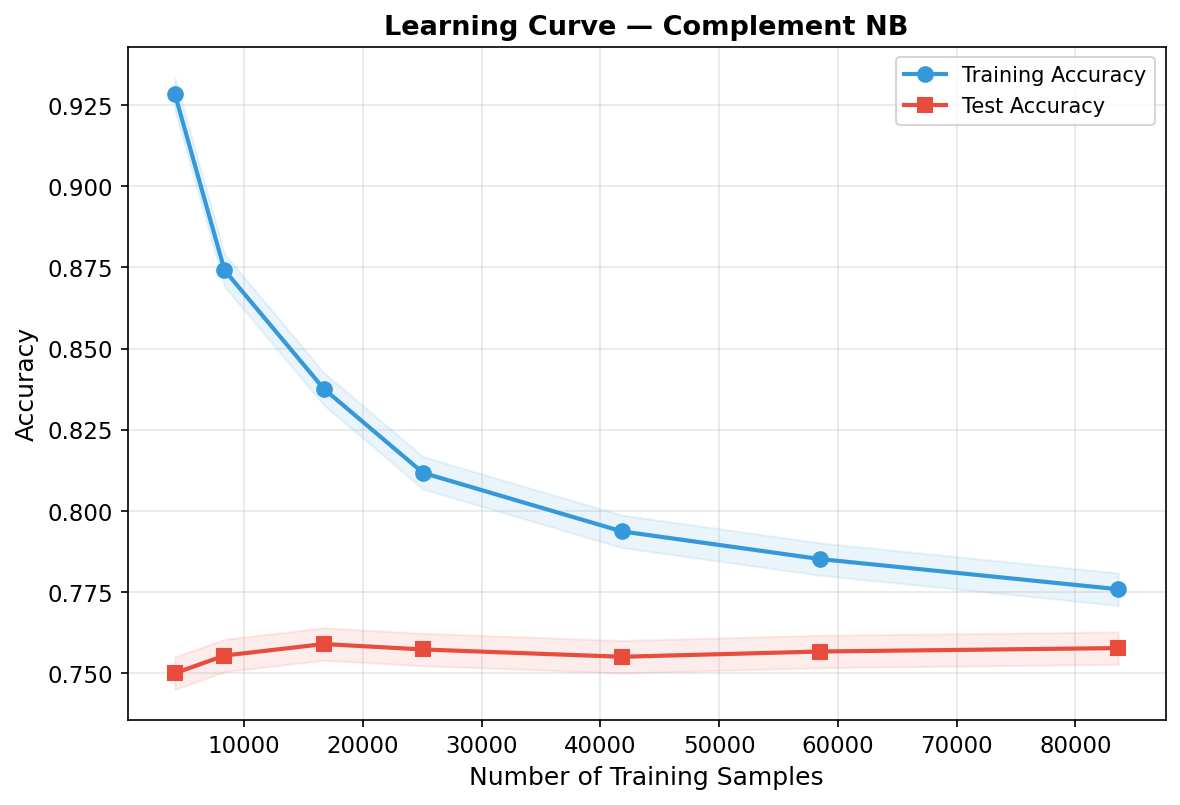

In [9]:
for name, v in results.items():
    plot_learning_curve(v['model'], X_tr, y_train, X_te, y_test, name, FIGURES_DIR)

## Alpha (Smoothing) Sensitivity

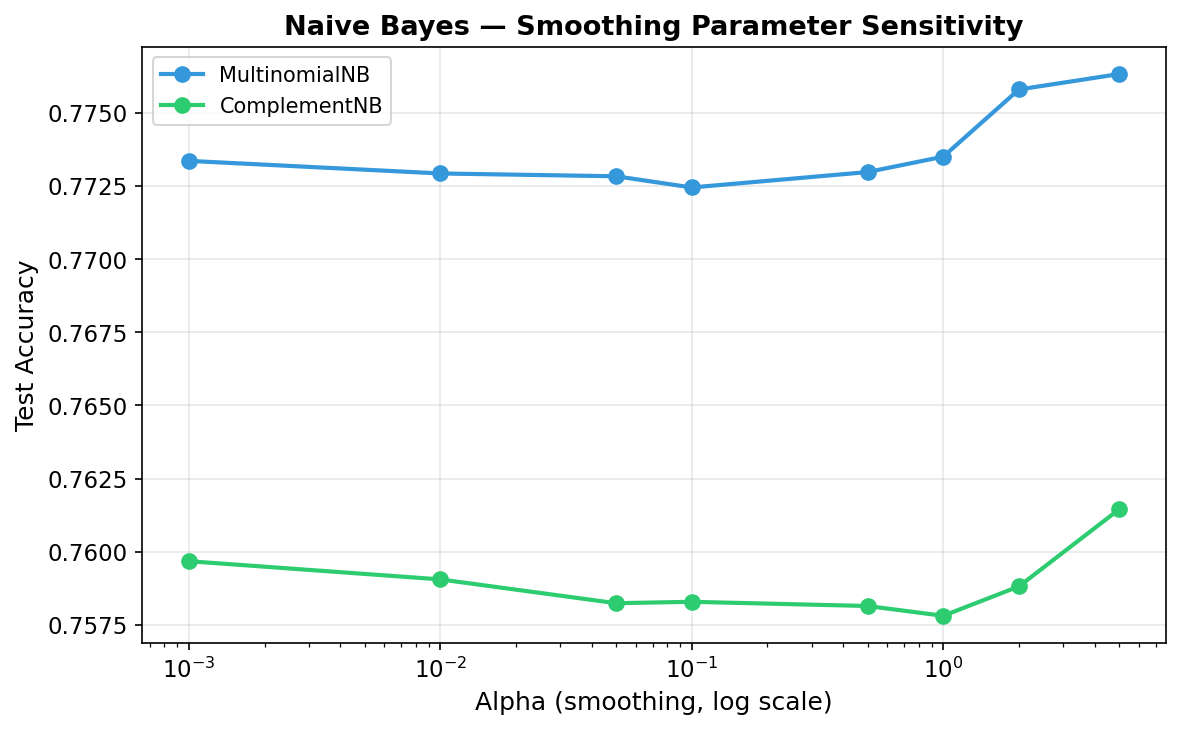

In [10]:
alphas = [0.001, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]
fig, ax = plt.subplots(figsize=(8, 5))
for ModelClass, color, name in [
    (MultinomialNB, '#3498db', 'MultinomialNB'),
    (ComplementNB,  '#2ecc71', 'ComplementNB'),
]:
    accs = []
    for a in alphas:
        m = ModelClass(alpha=a)
        m.fit(X_tr, y_train)
        accs.append(accuracy_score(y_test, m.predict(X_te)))
    ax.semilogx(alphas, accs, 'o-', color=color, lw=2, ms=7, label=name)
ax.set_xlabel('Alpha (smoothing, log scale)')
ax.set_ylabel('Test Accuracy')
ax.set_title('Naive Bayes — Smoothing Parameter Sensitivity')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'naive_bayes_alpha_sensitivity.png'), dpi=150, bbox_inches='tight')
plt.show()